# FLUX.2 [Klein] — Baseball Cap Generation

Generates the "cap" edit for every identity in `sampled_dataset.csv` (720 identities, glasses-filtered, balanced across 24 demographic cells).

Same model and pipeline call as the earlier timing test: `black-forest-labs/FLUX.2-klein-base-4B`, `guidance_scale=4.0`, 50 inference steps.

**Checkpointing**: a text file (`cap_checkpoint.txt`) records the hash of every identity successfully edited so far, one per line. On every run, already-completed hashes are skipped -- safe to stop and resume at any point (e.g. after a Colab disconnect).

**Output**: new images saved to `generated_cap/` as `<hash>_hat.png`. Nothing is written back into `generated_portraits_hashed_final/`.

**Logging**: uses Python's `logging` module instead of bare `print`, so every run has a timestamped record of what happened (including skips and any failures).

## 1. Setup

In [1]:
!pip install -q -U diffusers transformers accelerate huggingface_hub pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 74.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 34.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 76.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.


In [4]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    datefmt="%H:%M:%S",
    force=True,  # Colab sometimes pre-configures logging; force our format to take effect
)
#logger = logging.getLogger("cap_generation")
logger = logging.getLogger("glasses_generation")

In [5]:
import torch

logger.info(f"GPU available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    logger.info(f"GPU name: {torch.cuda.get_device_name(0)}")

20:21:25 [INFO] GPU available: True
20:21:25 [INFO] GPU name: Tesla T4


## 2. Mount Drive and locate the dataset

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

# Search Drive for the folder containing sampled_dataset.csv, since the notebook
# lives in the same folder as the data.
DATASET_DIR = None
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "sampled_dataset.csv" in files:
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError("Could not find sampled_dataset.csv anywhere under /content/drive/MyDrive")

logger.info(f"Found dataset folder: {DATASET_DIR}")

CSV_PATH = os.path.join(DATASET_DIR, "sampled_dataset.csv")
SOURCE_IMAGES_DIR = os.path.join(DATASET_DIR, "generated_portraits_hashed_final")
OUTPUT_DIR = os.path.join(DATASET_DIR, "generated_cap")
CHECKPOINT_PATH = os.path.join(DATASET_DIR, "cap_checkpoint.txt")

os.makedirs(OUTPUT_DIR, exist_ok=True)

logger.info(f"CSV: {CSV_PATH}")
logger.info(f"Source images: {SOURCE_IMAGES_DIR}")
logger.info(f"Output folder: {OUTPUT_DIR}")
logger.info(f"Checkpoint file: {CHECKPOINT_PATH}")

FileNotFoundError: Could not find sampled_dataset.csv anywhere under /content/drive/MyDrive

## 3. Load the sampled dataset and build a hash -> path lookup

One folder walk instead of one `glob()` per hash (per the earlier fix -- doing this per-hash was the bottleneck that made the glasses-detector step hang for minutes).

In [8]:
import pandas as pd

df = pd.read_csv(CSV_PATH)
logger.info(f"Loaded {len(df):,} identities from sampled_dataset.csv")

20:24:30 [INFO] NumExpr defaulting to 2 threads.


NameError: name 'CSV_PATH' is not defined

In [ ]:
import glob

all_image_files = [f for f in glob.glob(os.path.join(SOURCE_IMAGES_DIR, "**", "*"), recursive=True) if os.path.isfile(f)]
hash_to_path = {os.path.splitext(os.path.basename(f))[0]: f for f in all_image_files}
logger.info(f"Built lookup for {len(hash_to_path):,} source images")

df["IMAGE_PATH"] = df["HASH"].map(hash_to_path)
missing = df["IMAGE_PATH"].isna().sum()
if missing:
    logger.warning(f"{missing} hashes from sampled_dataset.csv had no matching source image file")
df = df.dropna(subset=["IMAGE_PATH"]).reset_index(drop=True)
logger.info(f"{len(df):,} identities ready for generation")

18:50:27 [INFO] Built lookup for 12,393 source images
18:50:27 [INFO] 720 identities ready for generation


## 4. Checkpoint: load already-completed hashes

`cap_checkpoint.txt` holds one hash per line -- every identity successfully edited in a previous run. Anything in this file is skipped below.

In [ ]:
def load_checkpoint(path):
    if not os.path.exists(path):
        return set()
    with open(path, "r") as f:
        return set(line.strip() for line in f if line.strip())

def append_checkpoint(path, hash_value):
    with open(path, "a") as f:
        f.write(hash_value + "\n")

completed_hashes = load_checkpoint(CHECKPOINT_PATH)
logger.info(f"Checkpoint file has {len(completed_hashes):,} already-completed hashes")

remaining_df = df[~df["HASH"].isin(completed_hashes)].reset_index(drop=True)
logger.info(f"{len(remaining_df):,} identities remaining to generate (out of {len(df):,} total)")

18:50:27 [INFO] Checkpoint file has 0 already-completed hashes
18:50:27 [INFO] 720 identities remaining to generate (out of 720 total)


## 5. Load FLUX.2 [Klein]

In [ ]:
from diffusers import Flux2KleinPipeline

logger.info("Loading FLUX.2 [Klein] pipeline...")
pipe = Flux2KleinPipeline.from_pretrained(
    "black-forest-labs/FLUX.2-klein-base-4B",
    torch_dtype=torch.bfloat16,
)
pipe.enable_model_cpu_offload()
logger.info("Pipeline loaded.")

18:50:41 [INFO] Loading FLUX.2 [Klein] pipeline...
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
18:50:42 [INFO] HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
18:50:42 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B "HTTP/1.1 200 OK"
18:50:42 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/main/model_index.json "HTTP/1.1 307 Temporary Redirect"
18:50:42 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/black-forest-labs/FLUX.2-klein-base-4B/a3b4f4849157f664bdbc776fd7453c2783562f4d/model_index.json?%2Fblack-forest-labs%2FFLUX.2-klein-base-4B%2Fresolve%2Fmain%2Fmodel_index.json=&etag=%228bd1147173cb71f16e20819cbb8b7955695f5a1

model_index.json:   0%|          | 0.00/422 [00:00<?, ?B/s]

18:50:42 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B/revision/main "HTTP/1.1 200 OK"
18:50:42 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B/tree/a3b4f4849157f664bdbc776fd7453c2783562f4d?recursive=true&expand=false "HTTP/1.1 200 OK"


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

18:50:43 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/a3b4f4849157f664bdbc776fd7453c2783562f4d/text_encoder/model-00001-of-00002.safetensors "HTTP/1.1 302 Found"
18:50:43 [INFO] HTTP Request: GET https://huggingface.co/api/models/black-forest-labs/FLUX.2-klein-base-4B/xet-read-token/a3b4f4849157f664bdbc776fd7453c2783562f4d "HTTP/1.1 200 OK"
18:50:43 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/a3b4f4849157f664bdbc776fd7453c2783562f4d/scheduler/scheduler_config.json "HTTP/1.1 307 Temporary Redirect"
18:50:43 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/a3b4f4849157f664bdbc776fd7453c2783562f4d/tokenizer/merges.txt "HTTP/1.1 307 Temporary Redirect"
18:50:43 [INFO] HTTP Request: HEAD https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B/resolve/a3b4f4849157f664bdbc776fd7453c2783562f4d/text_encoder/model.safetensors.index.json "HTTP

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

18:53:58 [INFO] Pipeline loaded.


In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

True
NVIDIA A100-SXM4-40GB


## 6. The cap edit prompt

First pass, not final -- refine after checking output quality (same "to be refined" caveat as the timing-test notebook).

In [ ]:
CAP_PROMPT = "add a plain baseball cap on the head, keep everything else the same"
SUFFIX = "hat"  # output filename suffix: <hash>_hat.png

## 7. Generate

Each successful edit: saved to disk, then its hash is appended to the checkpoint file immediately (not batched at the end), so a crash or disconnect mid-run never loses completed work.

In [ ]:
import time
from PIL import Image, ImageOps

TARGET_SIZE = 512

n_total = len(remaining_df)
n_done = 0
n_failed = 0
run_start = time.time()

logger.info(f"Starting generation: {n_total:,} identities to process")

for i, row in remaining_df.iterrows():
    h = row["HASH"]
    out_path = os.path.join(OUTPUT_DIR, f"{h}_{SUFFIX}.png")

    try:
        original_image = Image.open(row["IMAGE_PATH"]).convert("RGB")
        init_image = ImageOps.pad(
            original_image, (TARGET_SIZE, TARGET_SIZE),
            method=Image.LANCZOS, color=(255, 255, 255), centering=(0.5, 0.5),
        )

        t0 = time.time()
        result = pipe(
            image=init_image,
            prompt=CAP_PROMPT,
            guidance_scale=4.0,
            num_inference_steps=50,
            generator=torch.Generator(device="cuda").manual_seed(0),
        ).images[0]
        elapsed = time.time() - t0

        result.save(out_path)
        append_checkpoint(CHECKPOINT_PATH, h)
        n_done += 1

        avg_so_far = (time.time() - run_start) / n_done
        eta_min = (n_total - n_done) * avg_so_far / 60
        logger.info(
            f"[{n_done}/{n_total}] {h} -> {out_path} ({elapsed:.1f}s) "
            f"| avg {avg_so_far:.1f}s/img | ETA {eta_min:.1f} min"
        )

    except Exception as e:
        n_failed += 1
        logger.error(f"FAILED on {h}: {e}")
        # Not checkpointed -- will be retried on the next run.
        continue

total_elapsed = time.time() - run_start
logger.info(
    f"Run complete. {n_done:,} succeeded, {n_failed:,} failed, "
    f"{total_elapsed/60:.1f} min total this run."
)

18:56:13 [INFO] Starting generation: 720 identities to process


  0%|          | 0/50 [00:00<?, ?it/s]

18:56:41 [INFO] [1/720] 09534c3a20eaad55 -> /content/drive/MyDrive/Frugal AI Project/generated_cap/09534c3a20eaad55_hat.png (28.2s) | avg 28.9s/img | ETA 345.9 min


  0%|          | 0/50 [00:00<?, ?it/s]

18:57:07 [INFO] [2/720] 2522757e41af90a0 -> /content/drive/MyDrive/Frugal AI Project/generated_cap/2522757e41af90a0_hat.png (25.3s) | avg 27.3s/img | ETA 326.8 min


...

23:36:46 [INFO] [718/720] 7de85275e77b2d89 -> /content/drive/MyDrive/Frugal AI Project/generated_cap/7de85275e77b2d89_hat.png (23.1s) | avg 23.4s/img | ETA 0.8 min


  0%|          | 0/50 [00:00<?, ?it/s]

23:37:10 [INFO] [719/720] 2d17abef7513b47c -> /content/drive/MyDrive/Frugal AI Project/generated_cap/2d17abef7513b47c_hat.png (23.2s) | avg 23.4s/img | ETA 0.4 min


  0%|          | 0/50 [00:00<?, ?it/s]

23:37:33 [INFO] [720/720] a42b5980bbe630e5 -> /content/drive/MyDrive/Frugal AI Project/generated_cap/a42b5980bbe630e5_hat.png (23.1s) | avg 23.4s/img | ETA 0.0 min
23:37:33 [INFO] Run complete. 720 succeeded, 0 failed, 281.3 min total this run.


## 8. Verify against the checkpoint

In [ ]:
final_completed = load_checkpoint(CHECKPOINT_PATH)
logger.info(f"Checkpoint now has {len(final_completed):,} / {len(df):,} identities completed")

still_missing = set(df["HASH"]) - final_completed
if still_missing:
    logger.warning(f"{len(still_missing):,} identities still not completed. Rerun this notebook to continue.")
else:
    logger.info("All identities completed.")

23:37:33 [INFO] Checkpoint now has 720 / 720 identities completed
23:37:33 [INFO] All identities completed.


## 9. Visual spot check

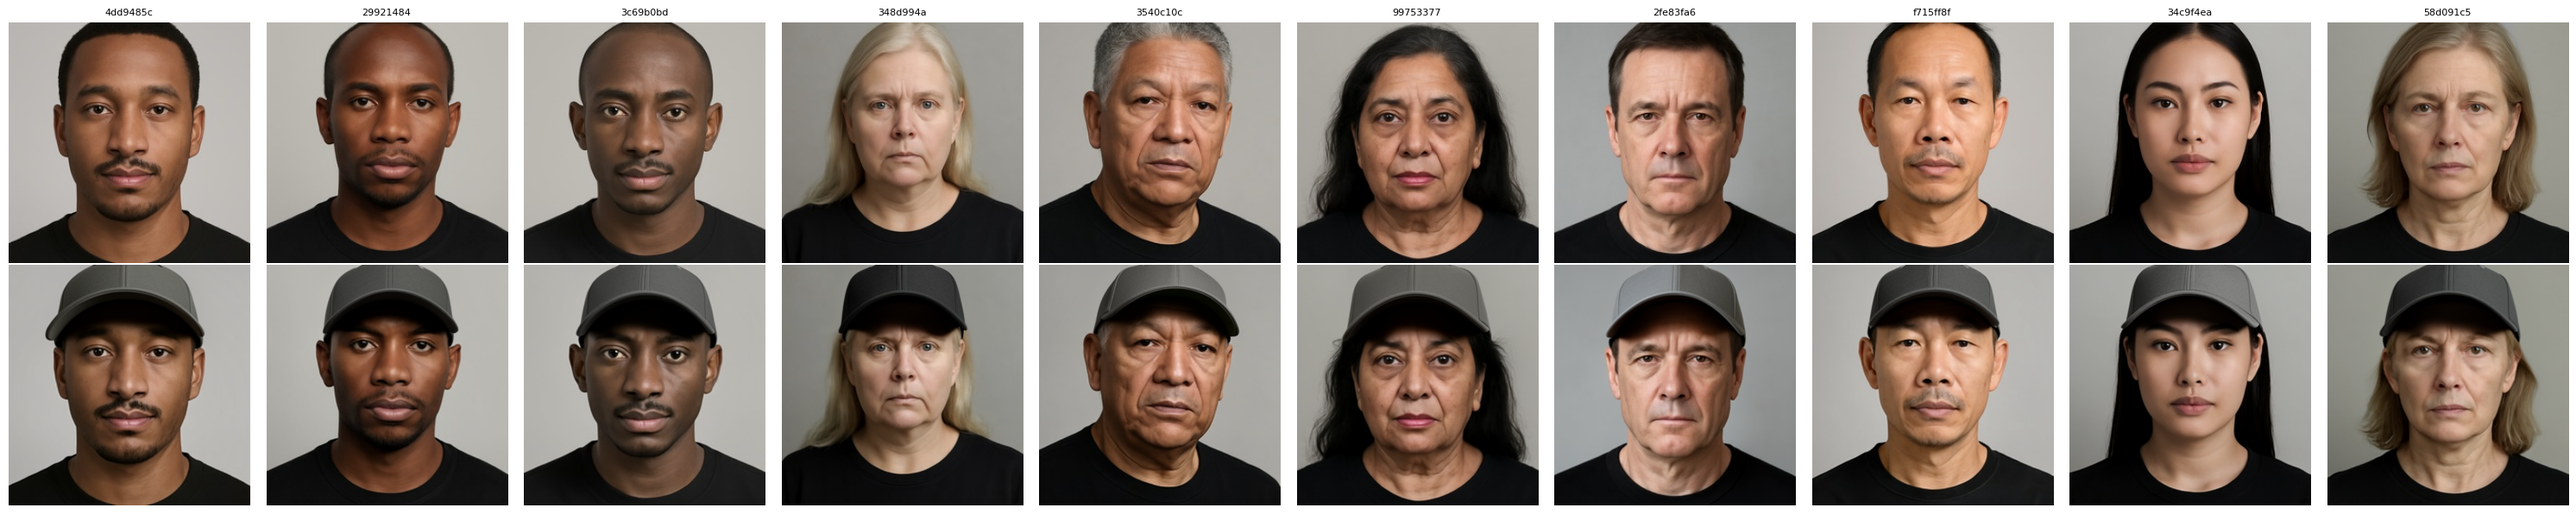

In [ ]:
import matplotlib.pyplot as plt

N_SPOT_CHECK = 10
spot_hashes = list(final_completed)[:N_SPOT_CHECK]

fig, axes = plt.subplots(2, len(spot_hashes), figsize=(3 * len(spot_hashes), 6))
for col, h in enumerate(spot_hashes):
    orig = Image.open(hash_to_path[h]).convert("RGB")
    edited = Image.open(os.path.join(OUTPUT_DIR, f"{h}_{SUFFIX}.png")).convert("RGB")
    axes[0, col].imshow(orig)
    axes[0, col].set_title(h[:8], fontsize=8)
    axes[0, col].axis("off")
    axes[1, col].imshow(edited)
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("+ Cap", fontsize=10)
plt.tight_layout()
plt.show()